# Module 1: Test-Time Compute Strategies on GSM8K

This notebook explores test-time compute strategies from Module one of Stanford's CS329A course, Self-Improving Agents. The question we will explore is: **when a small model gets more inference-time work, how much better can it reason on GSM8K?**

We keep generation and selection separate where possible:

- Generate multiple answer candidates to solve math problems.
- Freeze generated candidate pools before comparing selection rules.
- Try several selection and revision methods.
- Compare accuracy, token cost, and failure modes.

### Notebook Structure

**Part 1 (Baseline):** Generate one answer per question.

**Part 2 (Best-of-N Majority Vote):** Generate multiple candidates per question, freeze that pool, then apply majority vote for self-consistency.

**Part 3 (Difficulty bins):** Estimate problem difficulty from exact pass rate for analysis and answer agreement for possible routing.

**Part 4 (Medium/Hard revisions):** Count medium and hard problems, then apply sequential revisions to those categories to test whether depth helps where the model struggles.

The notebook tests whether extra inference-time compute improves accuracy enough to justify the additional token cost.


## Part 0 - Setup & EDA

Install required packages, load GSM8K, and load a lightweight reasoning model. The default model is set in the shared configuration cell so you can adjust runtime and quality in one place.

Default reasoning model: `microsoft/Phi-4-mini-reasoning`. Microsoft released this dedicated reasoning variant for Phi-4 Mini with a focus on multi-step mathematical reasoning, making it a strong fit for GSM8K-style experiments.

This model choice is well aligned with the notebook's self-consistency, selection-rule comparisons, GSM8K reasoning studies, and test-time compute scaling experiments. The model is compact enough for practical 4-bit notebook runs while being explicitly tuned for reasoning-heavy math workflows.

Default model card: https://huggingface.co/microsoft/Phi-4-mini-reasoning


In [1]:
!pip -q install -U bitsandbytes transformers accelerate datasets


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 45.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 150.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 529.0/529.0 kB 50.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 MB 54.0 MB/s eta 0:00:00


In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from datasets import load_dataset

import torch
import json
import pandas as pd

import time

### Shared Experiment Parameters
The following parameters are used throughout the experiment.


In [21]:
# Shared experiment settings

# Model used for all experiments
MODEL_NAME = "microsoft/Phi-4-mini-reasoning"
# Number of training examples
TRAIN_SUBSET_SIZE = 1000

# Number of evaluation examples
EVAL_SUBSET_SIZE = 500

# Max evaluation questions to run
EVAL_MAX_QUESTIONS = 50


# Maximum generation length
MAX_NEW_TOKENS = 2500


# Shared generation temperature used by every experiment path
EXPERIMENT_TEMPERATURE = 0.8

# Baseline single-pass settings
BASELINE_N_SAMPLES = 1


# Proposal generation settings
PROPOSAL_N_SAMPLES = 5


# Revision chain settings
REVISION_CHAIN_STEPS = 3

# Store all settings in one config dictionary
EXPERIMENT_CONFIG = {
    "model_name": MODEL_NAME,
    "train_subset_size": TRAIN_SUBSET_SIZE,
    "eval_subset_size": EVAL_SUBSET_SIZE,
    "eval_max_questions": EVAL_MAX_QUESTIONS,
    "max_new_tokens": MAX_NEW_TOKENS,
    "baseline_n_samples": BASELINE_N_SAMPLES,
    "temperature": EXPERIMENT_TEMPERATURE,
    "proposal_n_samples": PROPOSAL_N_SAMPLES,
    "revision_chain_steps": REVISION_CHAIN_STEPS,
}


# Print config in JSON format
print(json.dumps(EXPERIMENT_CONFIG, indent=2))


{
  "model_name": "microsoft/Phi-4-mini-reasoning",
  "train_subset_size": 1000,
  "eval_subset_size": 500,
  "eval_max_questions": 50,
  "max_new_tokens": 2500,
  "baseline_n_samples": 1,
  "temperature": 0.8,
  "proposal_n_samples": 5,
  "revision_chain_steps": 3
}


### Shared Helper Utilities

Reusable code lives in `helpers.py` and is imported below as `hh`. You can look in the helper file for shared utilities such as evaluation functions and other code used across the notebook. Keeping those pieces in a separate file helps keep the notebook code clean, focused, and modular.


In [4]:
import importlib
import sys
from pathlib import Path

module_dir = Path.cwd() if (Path.cwd() / "helpers.py").exists() else Path("modules/01_test_time_compute")
if str(module_dir) not in sys.path:
    sys.path.insert(0, str(module_dir))

import helpers as hh
hh = importlib.reload(hh)

hh.load_notebook_helpers(globals())


### Load the GSM8K dataset and create train/eval subsets.


In [5]:
# ## Load and Prepare Dataset
dataset = load_dataset("gsm8k", "main")
print("Dataset loaded successfully!")

# Create subsets (adjust sizes in the shared config cell if you want)
train_subset = dataset["train"].select(range(TRAIN_SUBSET_SIZE))
eval_subset = dataset["test"].select(range(EVAL_SUBSET_SIZE))

train_df = train_subset.to_pandas()
eval_df = eval_subset.to_pandas()

print(f"Training subset: {len(train_df)} examples")
print(f"Evaluation subset: {len(eval_df)} examples")


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Dataset loaded successfully!
Training subset: 1000 examples
Evaluation subset: 500 examples


## Explore the Data

GSM8K is a collection of middle school math problems with questions and worked answers. It is a common benchmark dataset for assessing reasoning models.

First, we can convert the dataset to a pandas DataFrame for quick structural inspection.


In [6]:
train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])
print("GSM8K train size:", len(train_df))
print("GSM8K test size:", len(test_df))
# Show the first five rows
train_df.head()


GSM8K train size: 7473
GSM8K test size: 1319


,question,answer
0,Natalia sold clips to 48 of her friends in Apr...,Natalia sold 48/2 = <<48/2=24>>24 clips in May...
1,Weng earns $12 an hour for babysitting. Yester...,Weng earns 12/60 = $<<12/60=0.2>>0.2 per minut...
2,Betty is saving money for a new wallet which c...,"In the beginning, Betty has only 100 / 2 = $<<..."
3,"Julie is reading a 120-page book. Yesterday, s...",Maila read 12 x 2 = <<12*2=24>>24 pages today....
4,James writes a 3-page letter to 2 different fr...,He writes each friend 3*2=<<3*2=6>>6 pages a w...


We can also inspect a few training examples to confirm the question/answer format.


In [7]:
# Use the helper function to inspect the first three training examples.
for i in range(3):
    show_example(dataset["train"][i])



QUESTION:
 Natalia sold clips to 48 of her friends in April, and then she sold half as many clips in May. How many clips did Natalia sell altogether in April and May?

SOLUTION:
 Natalia sold 48/2 = <<48/2=24>>24 clips in May.
Natalia sold 48+24 = <<48+24=72>>72 clips altogether in April and May.
#### 72

QUESTION:
 Weng earns $12 an hour for babysitting. Yesterday, she just did 50 minutes of babysitting. How much did she earn?

SOLUTION:
 Weng earns 12/60 = $<<12/60=0.2>>0.2 per minute.
Working 50 minutes, she earned 0.2 x 50 = $<<0.2*50=10>>10.
#### 10

QUESTION:
 Betty is saving money for a new wallet which costs $100. Betty has only half of the money she needs. Her parents decided to give her $15 for that purpose, and her grandparents twice as much as her parents. How much more money does Betty need to buy the wallet?

SOLUTION:
 In the beginning, Betty has only 100 / 2 = $<<100/2=50>>50.
Betty's grandparents gave her 15 * 2 = $<<15*2=30>>30.
This means, Betty needs 100 - 50 - 30 

## Answer Pattern and Regex

GSM8K solutions end with a standardized final-answer line:

- The final numeric answer appears after `####`
- It is usually on its own line
- It may be an integer or decimal

Because this format is consistent, we can use the `final_re` regex from `helpers.py` to extract the final answer for scoring.


In [8]:
# Regex is defined in helpers.py
print("Final answer regex:", final_re.pattern)


Final answer regex: ####\s*([-+]?\d+(?:\.\d+)?)


Each solution includes reasoning plus a final answer. The helper `extract_true_answer` parses the full solution and keeps only the numeric value after `####`.


In [9]:
dataset = dataset.map(lambda x: {"true_answer": extract_true_answer(x)})


Verify that the extracted `true_answer` aligns with the original `answer` text.


In [10]:
for i in range(3):
    show_example(dataset["train"][i])



QUESTION:
 Natalia sold clips to 48 of her friends in April, and then she sold half as many clips in May. How many clips did Natalia sell altogether in April and May?

SOLUTION:
 Natalia sold 48/2 = <<48/2=24>>24 clips in May.
Natalia sold 48+24 = <<48+24=72>>72 clips altogether in April and May.
#### 72

TRUE ANSWER: 72

QUESTION:
 Weng earns $12 an hour for babysitting. Yesterday, she just did 50 minutes of babysitting. How much did she earn?

SOLUTION:
 Weng earns 12/60 = $<<12/60=0.2>>0.2 per minute.
Working 50 minutes, she earned 0.2 x 50 = $<<0.2*50=10>>10.
#### 10

TRUE ANSWER: 10

QUESTION:
 Betty is saving money for a new wallet which costs $100. Betty has only half of the money she needs. Her parents decided to give her $15 for that purpose, and her grandparents twice as much as her parents. How much more money does Betty need to buy the wallet?

SOLUTION:
 In the beginning, Betty has only 100 / 2 = $<<100/2=50>>50.
Betty's grandparents gave her 15 * 2 = $<<15*2=30>>30.
This

## Model Setup

We will use the Phi-4 Mini reasoning model configured by `MODEL_NAME`:

- **Type:** Causal language model, or decoder-only transformer
- **Use case:** Step-by-step GSM8K reasoning, self-consistency, and test-time compute experiments
- **Model fit:** Microsoft released a dedicated reasoning variant for Phi-4 Mini focused on multi-step mathematical reasoning, while keeping the model small enough for Colab/Kaggle 4-bit runs

The configured model is loaded with **4-bit quantization** through `bitsandbytes` to reduce GPU memory use while preserving the notebook's reasoning-focused workflow.


### Check GPU Availability


In [11]:
# Check GPU Availability
print("CUDA Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Compute Capability:", torch.cuda.get_device_capability(0))


CUDA Available: True
GPU: NVIDIA A100-SXM4-40GB
Compute Capability: (8, 0)


### Load the model (4-bit quantized)


In [12]:
# Load Model with 4-bit Quantization (Lightweight)
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16
)

model_name = MODEL_NAME


tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=True)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=quantization_config,
    device_map="auto",
    torch_dtype=torch.bfloat16
)

model.eval()
print("Model loaded:", model_name)


[transformers] This model config has set a `rope_parameters['original_max_position_embeddings']` field, to be used together with `max_position_embeddings` to determine a scaling factor. Please set the `factor` field of `rope_parameters`with this ratio instead -- we recommend the use of this field over `original_max_position_embeddings`, as it is compatible with most model architectures.


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Model loaded: microsoft/Phi-4-mini-reasoning


### Shared Reasoning Prompt

The sample preview, baseline run, and Best-of-N proposal pool all use the same system prompt below. The prompt asks the model to reason step by step before giving a final numeric answer, which makes the generated solutions easier to inspect and gives self-consistency multiple reasoning paths to compare.

For GSM8K scoring, the final answer should still end with the dataset-friendly `#### <number>` format.


In [13]:
# Central prompt for the preview, baseline, and Best-of-N proposal generations.
BASELINE_PROMPT = """You are a careful math tutor. Solve each problem by reasoning step by step, focusing only on essential calculations and keeping your response concise.
Show the calculations needed to reach the answer, then finish with exactly one final line in this format:
#### <number>. """

print(BASELINE_PROMPT)

You are a careful math tutor. Solve each problem by reasoning step by step, focusing only on essential calculations and keeping your response concise.
Show the calculations needed to reach the answer, then finish with exactly one final line in this format:
#### <number>. 


### Sample 5 Examples

Before completing a full run, we sample five questions to confirm that the model is following the prompt, producing extractable final answers, and staying within the token budget.

The preview results look as expected: all five sampled answers were scored correct, and the generated responses stayed below `MAX_NEW_TOKENS`. The output-token range was 442 to 1,900 tokens, with an average of about 955 tokens, so the current max-token limit leaves enough room for these responses.


In [14]:
preview_token_df, preview_token_stats = build_token_preview(
    eval_df,
    model=model,
    tokenizer=tokenizer,
    n=5,
    temperature=EXPERIMENT_TEMPERATURE,
    max_new_tokens=MAX_NEW_TOKENS,
    system_prompt=BASELINE_PROMPT,
)


5-sample preview: 100%|██████████| 5/5 [04:00<00:00, 48.05s/it]


In [15]:
show_token_metrics_preview(preview_token_df, preview_token_stats)


Five-sample output-token EDA:


,metric,tokens
0,low_output_tokens,442.0
1,avg_output_tokens,955.4
2,high_output_tokens,1900.0


,idx,output_tokens,input_tokens,total_tokens,correct,true_answer,predicted_answer
0,90,1254,154,1408,True,225,225
1,254,593,133,726,True,84,84
2,283,1900,157,2057,True,68,68
3,445,588,139,727,True,6,6
4,461,442,105,547,True,9,9


Next, inspect a generated response in a human-readable format. The preview confirms that the model is reasoning step by step and ending with the expected `#### <number>` answer format.

In [16]:
show_token_human_readable_preview(preview_token_df, example_index=1)


Human-readable example
Preview row: 1
Question idx: 254
Output tokens: 593
Correct: True
True answer: 84
Predicted answer: 84

Question:

Shelly's 3 kids spent all day at the water park.  Mitchel went down the water slide 30 times.  Anne went down the slide 30% less than Mitchel and Robert went down 4 times as much as Anne.  How many times did Robert go down the water slide?

Final output:

<think>
Okay, let's see. So the problem is about Shelly's three kids who went down the water slide multiple times at the water park. The kids are Mitchel, Anne, and Robert. We need to find out how many times Robert went down the slide.

First, let's break down the information given. Mitchel went down the slide 30 times. That's straightforward. Then, Anne went down the slide 30% less than Mitchel. Hmm, percentage decrease. So I need to calculate 30% of Mitchel's 30 times and subtract that from Mitchel's total to find Anne's number. 

Let me write that out. If Mitchel went 30 times, then 30% of 30 is

In [17]:
show_token_human_readable_preview(preview_token_df, example_index=2)


Human-readable example
Preview row: 2
Question idx: 283
Output tokens: 1900
Correct: True
True answer: 68
Predicted answer: 68

Question:

Katerina makes designer jewelry.  Her specialty is topaz necklaces.  She uses 8 topaz gemstones per necklace, and fills the space between gemstones using sterling silver beads.  If each topaz gemstone is one inch long, each sterling silver bead is one-quarter of an inch long, and each necklace is made to a total length of 25 inches, how many sterling silver beads does Katerina use per necklace?

Final output:

<think>
Okay, let's see. Katerina makes designer necklaces using topaz gemstones and sterling silver beads. The problem is asking how many sterling silver beads she uses per necklace. Let me break down the information given:

First, each necklace uses 8 topaz gemstones. Each topaz is one inch long. So, the total length taken up by the topaz stones would be 8 times one inch. Let me write that down: 8 topazes × 1 inch per topaz = 8 inches. That

Inspecting another sampled response gives the same sanity check: the reasoning is readable, the final answer is extractable, and the response is not running into the token limit.


In [18]:
# Try another row, for example:
show_token_human_readable_preview(preview_token_df, example_index=4)



Human-readable example
Preview row: 4
Question idx: 461
Output tokens: 442
Correct: True
True answer: 9
Predicted answer: 9

Question:

Shondra has 7 fewer plants than Toni. Toni has 60% more plants than Frederick. If Frederick has 10 plants, how many plants does Shondra have?

Final output:

<think>
Okay, let's see. So the problem is about Shondra, Toni, and Frederick having plants. Let me try to break it down step by step.

First, Frederick has 10 plants. That's given. Then, Toni has 60% more plants than Frederick. Hmm, okay. So I need to figure out how many plants Toni has based on Frederick's number. Then, Shondra has 7 fewer plants than Toni. So once I know Toni's total, subtract 7 to get Shondra's count. Let me make sure I follow each part correctly.

Starting with Frederick: 10 plants. Now, Toni has 60% more than that. To calculate 60% more than Frederick's plants, I think you take Frederick's number and add 60% of it. So, 60% of 10 is 0.6 * 10 = 6. So Toni has 10 + 6 = 16 plan

After checking a few sampled outputs, the baseline run can use the same shared prompt and answer-extraction path at a larger scale.


### Part 1 — Run Baseline

The baseline is the simplest evaluation setting: the model produces one response per question, and that single extracted answer is scored directly.

Here we evaluate the model on a subset of the GSM8K evaluation set using the shared notebook configuration:

- `BASELINE_N_SAMPLES`
- `EXPERIMENT_TEMPERATURE`
- `EVAL_MAX_QUESTIONS`
- `MAX_NEW_TOKENS`

This gives us a reference point before adding extra inference-time compute through self-consistency.


In [19]:
baseline_metrics, baseline_results = evaluate(
    eval_df=eval_df,
    model=model,
    tokenizer=tokenizer,
    n_samples=BASELINE_N_SAMPLES,
    temperature=EXPERIMENT_TEMPERATURE,
    max_questions=EVAL_MAX_QUESTIONS,
    max_new_tokens=MAX_NEW_TOKENS,
    system_prompt=BASELINE_PROMPT,
)

# Extract key values
baseline_acc = baseline_metrics["accuracy"]
baseline_q = baseline_metrics["num_questions"]
baseline_correct = baseline_metrics["num_correct"]

print("Baseline metrics:")
print(json.dumps(baseline_metrics, indent=2))
print("\nSummary:")

print(f"Correct: {baseline_correct} / {baseline_q}")
print(f"Accuracy: {baseline_acc:.2%}")


Eval: baseline: 100%|██████████| 50/50 [39:09<00:00, 46.99s/it]

Baseline metrics:
{
  "accuracy": 0.68,
  "num_questions": 50,
  "num_correct": 34,
  "n_samples": 1,
  "temperature": 0.8,
  "max_new_tokens": 2500,
  "selection_mode": "majority_vote",
  "system_prompt": "You are a careful math tutor. Solve each problem by reasoning step by step, focusing only on essential calculations and keeping your response concise.\nShow the calculations needed to reach the answer, then finish with exactly one final line in this format:\n#### <number>. ",
  "elapsed_sec": 2349.498373746872,
  "avg_input_tokens_per_question": 126.68,
  "avg_new_tokens_per_question": 944.36,
  "avg_total_tokens_per_question": 1071.04
}

Summary:
Correct: 34 / 50
Accuracy: 68.00%


The baseline run gives the cheapest reference point: one generated answer per question. In this run, Phi-4 Mini Reasoning answered **34 / 50** questions correctly, for **68% accuracy**.

The next sections test whether spending more inference-time compute can improve on that baseline.


### Part 2 — Self-Consistency from a Frozen Proposal Pool

We first generate a **single frozen pool of candidate solutions** for each question. The sample count, temperature, question limit, and max-token cap come from the shared configuration cell.

Self-consistency then selects the final answer by applying **majority vote** to those frozen candidates. The same frozen pool is also reused in Part 3 to estimate empirical difficulty, so we do not regenerate samples just to build difficulty bins.

For example, if the sampled answers are `[18, 18, 22]`, the final prediction is **18** based on majority vote.


In [22]:
# Build one frozen proposal pool for Part 2 self-consistency and Part 3 difficulty bins
proposal_pool, proposal_pool_meta = build_generation_pool(
    eval_df=eval_df,
    model=model,
    tokenizer=tokenizer,
    n_samples=PROPOSAL_N_SAMPLES,
    temperature=EXPERIMENT_TEMPERATURE,
    max_questions=EVAL_MAX_QUESTIONS,
    max_new_tokens=MAX_NEW_TOKENS,
    system_prompt=BASELINE_PROMPT,
)

print("Frozen proposal pool built.")
print(json.dumps(proposal_pool_meta, indent=2))


Build generation pool (n=5): 100%|██████████| 50/50 [3:29:09<00:00, 251.00s/it]

Frozen proposal pool built.
{
  "num_questions": 50,
  "n_samples": 5,
  "temperature": 0.8,
  "system_prompt": "You are a careful math tutor. Solve each problem by reasoning step by step, focusing only on essential calculations and keeping your response concise.\nShow the calculations needed to reach the answer, then finish with exactly one final line in this format:\n#### <number>. ",
  "avg_input_tokens_per_question": 633.4,
  "avg_new_tokens_per_question": 5011.96,
  "avg_total_tokens_per_question": 5645.36
}


In [23]:
sc_metrics, sc_results = evaluate_from_generation_pool(
    generation_pool=proposal_pool,
    pool_meta=proposal_pool_meta,
    selection_mode="majority_vote",
)

sc_acc = sc_metrics["accuracy"]
sc_q = sc_metrics["num_questions"]
sc_correct = sc_metrics["num_correct"]

print("Self-consistency metrics:")
print(json.dumps(sc_metrics, indent=2))

print("\nSummary:")
print(f"Correct: {sc_correct} / {sc_q}")
print(f"Accuracy: {sc_acc:.2%}")


Self-consistency metrics:
{
  "accuracy": 0.8,
  "num_questions": 50,
  "num_correct": 40,
  "n_samples": 5,
  "temperature": 0.8,
  "selection_mode": "majority_vote",
  "elapsed_sec": 0.00040149688720703125,
  "avg_input_tokens_per_question": 633.4,
  "avg_new_tokens_per_question": 5011.96,
  "avg_total_tokens_per_question": 5645.36
}

Summary:
Correct: 40 / 50
Accuracy: 80.00%


Self-consistency improved the result on this sample. Majority vote over the frozen proposal pool answered **40 / 50** questions correctly, raising accuracy from **68%** to **80%**.

The improvement came at a clear compute cost: the proposal pool used about **5,645 tokens per question** on average, compared with about **1,071 tokens** for the single-answer baseline.


## Part 3 — Difficulty Binning (Easy / Medium / Hard)

In this section, we estimate problem difficulty from the frozen proposal pool.

We keep two related signals:

- **Pass-rate difficulty:** uses the known answer, so it is useful for analysis and hard-bin diagnostics.
- **Agreement difficulty:** uses only agreement among sampled model answers, so it can support a future routing policy without answer-label leakage.

Pass-rate difficulty uses the original pass-rate thresholds: easy at 0.8 or higher, medium at 0.3 or higher, and hard otherwise. Agreement difficulty uses answer-agreement thresholds: easy at 0.8 or higher, medium at 0.5 or higher, and hard otherwise.


In [24]:
difficulty_df = build_difficulty_table_from_pool(proposal_pool)

print("Pass-rate difficulty counts:")
print(difficulty_df["difficulty"].value_counts())

print("\nRouting difficulty counts:")
print(difficulty_df["routing_difficulty"].value_counts())

eval_with_diff = attach_difficulty_columns(eval_df, difficulty_df)

difficulty_df.head()


Pass-rate difficulty counts:
difficulty
easy      32
medium    10
hard       8
Name: count, dtype: int64

Routing difficulty counts:
routing_difficulty
easy      34
medium     9
hard       7
Name: count, dtype: int64


,idx,question,true_answer,pass_rate,difficulty,answer_agreement,routing_difficulty,n_samples_used
0,0,Janet’s ducks lay 16 eggs per day. She eats th...,18,1.0,easy,1.0,easy,5
1,1,A robe takes 2 bolts of blue fiber and half th...,3,1.0,easy,1.0,easy,5
2,2,Josh decides to try flipping a house. He buys...,70000,0.4,medium,0.4,hard,5
3,3,James decides to run 3 sprints 3 times a week....,540,0.2,hard,0.6,medium,5
4,4,"Every day, Wendi feeds each of her chickens th...",20,1.0,easy,1.0,easy,5


## Part 4 — Medium/Hard Sequential Revisions (Self-Refinement)

Here we focus on the questions that the difficulty binning marked as **medium** or **hard**. First, we report how many questions landed in each category and how often the current self-consistency answer was correct. Then we apply sequential self-revision separately to each category and compare the updated results.

For each selected problem, we generate and freeze one **revision chain**:

- **Attempt 0:** baseline solution
- **Attempts 1..R:** revised solutions conditioned on the previous attempt

The primary post-revision score uses the final revision attempt. We also keep a majority-vote selector over each revision chain as an alternate diagnostic.


### Sequential Revision Prompts

The medium/hard revision experiment uses the same base reasoning prompt for attempt 0, then switches to a revision-specific system prompt and user prompt template for later attempts. Keeping these prompts in the notebook makes the revision behavior explicit and keeps `helpers.py` focused on reusable mechanics.

The revision prompt asks the model to inspect its earlier reasoning, correct mistakes, and again finish with the `#### <number>` answer format used by GSM8K scoring.


In [25]:
# Attempt 0 uses BASELINE_PROMPT; revision attempts use this system prompt.
REVISION_SYSTEM_PROMPT = """You are a careful math tutor. Review the previous attempt, reason step by step about any mistakes, and produce a corrected solution.
Show the calculations needed to reach the answer, then finish with exactly one final line in this format:
#### <number>"""

# The helper fills these format fields for each revision step.
REVISION_PROMPT_TEMPLATE = """You previously attempted the following math problem.
Your earlier reasoning may contain mistakes. Carefully review it step by step, correct any errors, and produce an improved solution.
End your response with exactly one final numeric answer line formatted as #### <number>.

Question:
{question}

Previous attempt:
{previous_attempt_text}
"""

print(REVISION_SYSTEM_PROMPT)
print("\nRevision prompt template:\n")
print(REVISION_PROMPT_TEMPLATE)


You are a careful math tutor. Review the previous attempt, reason step by step about any mistakes, and produce a corrected solution.
Show the calculations needed to reach the answer, then finish with exactly one final line in this format:
#### <number>

Revision prompt template:

You previously attempted the following math problem.
Your earlier reasoning may contain mistakes. Carefully review it step by step, correct any errors, and produce an improved solution.
End your response with exactly one final numeric answer line formatted as #### <number>.

Question:
{question}

Previous attempt:
{previous_attempt_text}



First, summarize how the current self-consistency answers performed on the medium and hard bins before applying revisions.


In [26]:
# Part 4 uses every medium- and hard-bin problem identified in Part 3.
REVISION_DIFFICULTIES = ["medium", "hard"]

pre_revision_stats = summarize_difficulty_bin_performance(
    eval_with_diff=eval_with_diff,
    result_rows=sc_results,
    categories=REVISION_DIFFICULTIES,
    stage="Before revisions",
)

print("Medium/hard performance before revisions:")
pre_revision_stats


Medium/hard performance before revisions:


,stage,difficulty,total_questions,num_correct,accuracy,accuracy_pct
0,Before revisions,medium,10,8,0.8,80.0
1,Before revisions,hard,8,0,0.0,0.0


Next, split the evaluation rows into separate medium and hard revision sets.


In [27]:
revision_dfs = {
    difficulty: (
        eval_with_diff[eval_with_diff["difficulty"] == difficulty]
        .copy()
        .reset_index(drop=True)
    )
    for difficulty in REVISION_DIFFICULTIES
}

for difficulty, df in revision_dfs.items():
    print(f"{difficulty.title()} questions selected for revision: {len(df)}")

revision_dfs["medium"][["idx", "difficulty", "pass_rate", "question"]].head()


Medium questions selected for revision: 10
Hard questions selected for revision: 8


,idx,difficulty,pass_rate,question
0,2,medium,0.4,Josh decides to try flipping a house. He buys...
1,11,medium,0.4,Toula went to the bakery and bought various ty...
2,12,medium,0.4,Carlos is planting a lemon tree. The tree will...
3,15,medium,0.4,A merchant wants to make a choice of purchase ...
4,26,medium,0.4,"Mishka bought 3 pairs of shorts, 3 pairs of pa..."


Now generate frozen revision chains for every question in each selected difficulty bin.


In [28]:
revision_chain_pools = {}
revision_pool_meta = {}

for difficulty, revision_df in revision_dfs.items():
    pool, meta = build_revision_chain_pool(
        eval_df=revision_df,
        model=model,
        tokenizer=tokenizer,
        r_steps=REVISION_CHAIN_STEPS,
        base_temperature=EXPERIMENT_TEMPERATURE,
        rev_temperature=EXPERIMENT_TEMPERATURE,
        max_questions=None,  # Use all rows in this difficulty bin.
        max_new_tokens=MAX_NEW_TOKENS,
        base_system_prompt=BASELINE_PROMPT,
        revision_system_prompt=REVISION_SYSTEM_PROMPT,
        revision_prompt_template=REVISION_PROMPT_TEMPLATE,
    )
    revision_chain_pools[difficulty] = pool
    revision_pool_meta[difficulty] = meta

print("Revision chain pool metadata:")
print(json.dumps(revision_pool_meta, indent=2))


Build revision chains (R=3): 100%|██████████| 8/8 [23:33<00:00, 176.67s/it]

Revision chain pool metadata:
{
  "medium": {
    "num_questions": 10,
    "r_steps": 3,
    "base_temperature": 0.8,
    "rev_temperature": 0.8,
    "max_new_tokens": 2500,
    "base_system_prompt": "You are a careful math tutor. Solve each problem by reasoning step by step, focusing only on essential calculations and keeping your response concise.\nShow the calculations needed to reach the answer, then finish with exactly one final line in this format:\n#### <number>. ",
    "revision_system_prompt": "You are a careful math tutor. Review the previous attempt, reason step by step about any mistakes, and produce a corrected solution.\nShow the calculations needed to reach the answer, then finish with exactly one final line in this format:\n#### <number>",
    "revision_prompt_template": "You previously attempted the following math problem.\nYour earlier reasoning may contain mistakes. Carefully review it step by step, correct any errors, and produce an improved solution.\nEnd your resp

After generation, score each frozen revision chain using the final revision and a majority-vote diagnostic.


In [29]:
revision_metrics_last = {}
revision_rows_last = {}
revision_metrics_majority = {}
revision_rows_majority = {}

for difficulty in REVISION_DIFFICULTIES:
    revision_metrics_last[difficulty], revision_rows_last[difficulty] = evaluate_from_revision_chain_pool(
        revision_chain_pool=revision_chain_pools[difficulty],
        pool_meta=revision_pool_meta[difficulty],
        selection_mode="last",
    )
    revision_metrics_majority[difficulty], revision_rows_majority[difficulty] = evaluate_from_revision_chain_pool(
        revision_chain_pool=revision_chain_pools[difficulty],
        pool_meta=revision_pool_meta[difficulty],
        selection_mode="majority_vote",
    )

print("Revision metrics using final revision:")
print(json.dumps(revision_metrics_last, indent=2))


Eval revision pool: majority_vote: 100%|██████████| 8/8 [00:00<00:00, 47866.52it/s]

Revision metrics using final revision:
{
  "medium": {
    "method": "sequential_revisions",
    "accuracy": 0.9,
    "num_questions": 10,
    "num_correct": 9,
    "r_steps": 3,
    "base_temperature": 0.8,
    "rev_temperature": 0.8,
    "selection_mode": "last",
    "elapsed_sec": 1988.819237947464,
    "generation_elapsed_sec": 1988.8174710273743,
    "selection_elapsed_sec": 0.0017669200897216797,
    "avg_input_tokens_per_question": 3847.6,
    "avg_new_tokens_per_question": 3940.2,
    "avg_total_tokens_per_question": 7787.8
  },
  "hard": {
    "method": "sequential_revisions",
    "accuracy": 0.625,
    "num_questions": 8,
    "num_correct": 5,
    "r_steps": 3,
    "base_temperature": 0.8,
    "rev_temperature": 0.8,
    "selection_mode": "last",
    "elapsed_sec": 1413.3601434230804,
    "generation_elapsed_sec": 1413.3580844402313,
    "selection_elapsed_sec": 0.0020589828491210938,
    "avg_input_tokens_per_question": 3294.375,
    "avg_new_tokens_per_question": 3514.125,


Finally, compare medium, hard, and full-experiment performance before revisions against the updated post-revision results. The helper function below builds the dataframe, including the full-experiment rows where easy-bin self-consistency answers stay fixed and only medium/hard answers are replaced with revision outputs.


In [30]:
part4_before_after_summary = build_revision_before_after_summary(
    pre_revision_stats=pre_revision_stats,
    base_result_rows=sc_results,
    revision_rows_last=revision_rows_last,
    revision_rows_majority=revision_rows_majority,
    categories=REVISION_DIFFICULTIES,
)

part4_before_after_summary.style.format({"accuracy": "{:.2%}", "accuracy_pct": "{:.1f}%"})


,stage,difficulty,total_questions,num_correct,accuracy,accuracy_pct
0,Before revisions,medium,10,8,80.00%,80.0%
1,Before revisions,hard,8,0,0.00%,0.0%
2,After revisions (last),medium,10,9,90.00%,90.0%
3,After revisions (last),hard,8,5,62.50%,62.5%
4,After revisions (majority vote),medium,10,7,70.00%,70.0%
5,After revisions (majority vote),hard,8,4,50.00%,50.0%
6,Before revisions,all,50,40,80.00%,80.0%
7,After revisions (last),all,50,46,92.00%,92.0%
8,After revisions (majority vote),all,50,43,86.00%,86.0%


### Part 4 Results Summary

Sequential revision helped most on the targeted hard problems. Using the **final revision** as the answer improved medium questions from **8 / 10** to **9 / 10** and hard questions from **0 / 8** to **5 / 8**. Applied back to the full experiment, this raised the result from **40 / 50** after self-consistency to **46 / 50**.

Majority vote over the revision chain was weaker: **7 / 10** on medium, **4 / 8** on hard, and **43 / 50** overall. In this run, revision worked best when the final revised answer was trusted directly instead of voting across correlated revision attempts.


## Save Artifacts

Save the main results for reuse without rerunning the notebook.


In [31]:
# Keep the saved artifact tied to the exact prompts and frozen pools used above.
final_payload = build_experiment_payload(
    experiment_config=EXPERIMENT_CONFIG,
    baseline_metrics=baseline_metrics,
    proposal_pool_meta=proposal_pool_meta,
    baseline_prompt=BASELINE_PROMPT,
    revision_system_prompt=REVISION_SYSTEM_PROMPT,
    revision_prompt_template=REVISION_PROMPT_TEMPLATE,
    preview_token_stats=preview_token_stats,
    preview_token_df=preview_token_df,
    baseline_results=baseline_results,
    sc_metrics=sc_metrics,
    sc_results=sc_results,
    difficulty_df=difficulty_df,
    revision_pool_meta=revision_pool_meta,
    revision_chain_pool=revision_chain_pools,
    rev_last_metrics=revision_metrics_last,
    rev_mv_metrics=revision_metrics_majority,
)

write_json_artifact(final_payload, "gsm8k_test_time_compute_results.json")


Wrote gsm8k_test_time_compute_results.json


'gsm8k_test_time_compute_results.json'

## Final Results

The completed run supports the project hypothesis: extra test-time compute improved Phi-4 Mini Reasoning on this small GSM8K sample. The baseline scored **34 / 50**, self-consistency scored **40 / 50**, and routed final revisions reached **46 / 50** when medium/hard answers were replaced with their final revisions.

The tradeoff is compute. Self-consistency used roughly **5.3x** more tokens per question than the baseline, and revision chains were even more expensive on the targeted bins. The revision rows below should be read as targeted diagnostics rather than standalone full-dataset accuracy rows.

The practical takeaway is not “always spend more.” It is to spend cheap compute broadly, then route uncertain or unresolved questions to deeper compute only when the extra work is likely to matter.


In [32]:
metrics_df = build_metrics_table({
    "Baseline": baseline_metrics,
    "Self-consistency": sc_metrics,
    "Medium revisions - last": revision_metrics_last["medium"],
    "Medium revisions - majority": revision_metrics_majority["medium"],
    "Hard revisions - last": revision_metrics_last["hard"],
    "Hard revisions - majority": revision_metrics_majority["hard"],
})

metrics_summary_view(metrics_df)


,method,accuracy,num_correct,num_questions,avg_tokens,elapsed_sec,selection_mode
0,Baseline,0.680,34,50,1071.04,2349.498374,majority_vote
1,Self-consistency,0.800,40,50,5645.36,0.000401,majority_vote
2,Medium revisions - last,0.900,9,10,7787.80,1988.819238,last
3,Medium revisions - majority,0.700,7,10,7787.80,1988.819289,majority_vote
4,Hard revisions - last,0.625,5,8,6808.50,1413.360143,last
5,Hard revisions - majority,0.500,4,8,6808.50,1413.359792,majority_vote


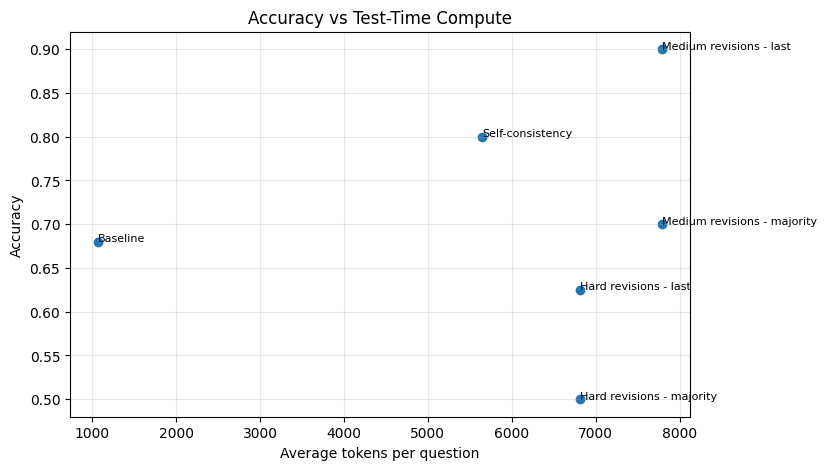

In [33]:
plot_accuracy_vs_compute(metrics_df)


## Conclusion

This project is complete. On this small 50-question GSM8K evaluation sample, Phi-4 Mini Reasoning improved as more structured test-time compute was added: **34 / 50** with one answer, **40 / 50** with self-consistency, and **46 / 50** after routing medium/hard questions through final revisions.

The result is encouraging, but it is not free. Accuracy improved because the model received more chances to solve and revise, while token usage and runtime increased substantially. The strongest strategy was targeted: use broader sampling to identify weaker cases, then spend deeper revision compute on those harder questions.

The main limitations are clear. The evaluation sample is small, the pass-rate difficulty bins use gold-answer information, revision rows are targeted diagnostics rather than full-dataset runs, and token counts are a cleaner compute comparison than wall-clock timing. A stronger follow-up would use more questions and multiple seeds, but this notebook now reports the completed run as-is.

A natural production-style extension is model routing. A small model can solve the easy or high-confidence problems first; unresolved, low-confidence, or likely incorrect questions can then be routed to a larger model. That could improve final accuracy while avoiding the cost of using the larger model on every example.

Overall, the notebook demonstrates the central lesson of test-time compute: small reasoning models can perform better when given structured opportunities to sample, vote, revise, and route. The useful version of this idea is compute-aware, targeted, and honest about its limitations.
